# 07 — Landmark time progression on practice d001 (1-year horizon, stichtags 2021→2026): does AUPRC improve?

**New dataframe, new question.** Input: `practice_1/landmarks_1j_2021_2026_d001.csv` — the CheCKD
Stage-1/Stage-2 SQL (`practice_1/CKD_risk_model_dataframe.sql`) run at **six rolling landmarks**
(every 1 July, 2021–2026) on practice d001, one row per patient per landmark, 1-year outcome
horizon (`horizont_jahre = 1`, so stichtag 2026-07-01 means the outcome window (2025-07-01,
2026-07-01] — fully observed).

Notebook 06 answered "can we predict CKD progression at one landmark on three horizons?".
This notebook answers the **time-progression** question:

> As the landmark rolls from 2021 to 2026 — more history behind every patient, a shifting
> practice population — does **AUPRC** (average precision) improve, or not?

**Single-practice, centralized** — like notebook 06, no federation anywhere here. Logistic
regression only (the project's sole model class; CLAUDE.md §0.2). The evaluation is *temporal*
in the deployment sense: a practice re-runs the extraction each year and re-trains; we measure
whether the yearly refresh actually buys predictive skill.

## 1. Setup

One global seed drives every split and resample (project reproducibility rule). Preprocessing
goes through the repo's single entry point (`data.loader.to_xy`, CheCKD dispatch) — no parallel
preprocessing is introduced here.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from data.loader import to_xy  # the single preprocessing entry point (CheCKD dispatch)

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
DATA = Path("../practice_1")
CSV = DATA / "landmarks_1j_2021_2026_d001.csv"
LABEL = "g3a"                      # G3a = the primary endpoint (notebook 06, CLAUDE.md §3b)
MIN_LABELLED_EVENTS = 10           # notebook-06 task gate

INK = "#1a1a1a"; BLUE = "#2b6cb0"; GREEN = "#2f855a"; RED = "#c53030"; GREY = "#718096"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.edgecolor": INK,
                     "axes.linewidth": 0.8, "axes.grid": False})

## 2. Load the landmark frame and gate the task

Contract checks: one practice, 1-year horizon on every row, unique (patient, landmark) pairs.
The G3b / G4 event counts are printed to justify the G3a-only analysis — the >=10-labelled-events
gate from notebook 06 decides which thresholds are defensible on one practice.

In [2]:
df = pd.read_csv(CSV)
assert df["praxis"].nunique() == 1, "expected a single practice"
assert df["horizont_jahre"].eq(1).all(), "expected the 1-year horizon on all rows"
assert not df.duplicated(subset=["patientid", "stichtag"]).any(), "expected one row per patient per landmark"

LANDMARKS = sorted(df["stichtag"].unique())
print(f"{len(df):,} rows | {df['patientid'].nunique():,} distinct patients | "
      f"{len(LANDMARKS)} landmarks: {LANDMARKS[0]} … {LANDMARKS[-1]}")

rows = []
for s in LANDMARKS:
    d = df[df["stichtag"] == s]
    row = {"stichtag": s, "rows": len(d), "cutoff": d["cutoff"].iloc[0]}
    for t in ("g3a", "g3b", "g4"):
        lab = d[f"label_{t}"]
        row[f"{t}: labelled"] = int(lab.notna().sum())
        row[f"{t}: events"] = int(lab.sum())
    row["g3a event rate"] = round(d["label_g3a"].mean(), 3)
    rows.append(row)
overview = pd.DataFrame(rows).set_index("stichtag")
overview

19,017 rows | 5,850 distinct patients | 6 landmarks: 2021-07-01 … 2026-07-01


,rows,cutoff,g3a: labelled,g3a: events,g3b: labelled,g3b: events,g4: labelled,g4: events,g3a event rate
stichtag,,,,,,,,,
2021-07-01,2955,2020-07-01,707,34,845,11,900,4,0.048
2022-07-01,2800,2021-07-01,701,14,858,11,907,1,0.020
2023-07-01,3111,2022-07-01,808,10,975,12,1025,2,0.012
2024-07-01,3336,2023-07-01,788,21,952,12,1007,4,0.027
2025-07-01,3403,2024-07-01,841,19,1012,11,1078,3,0.023
2026-07-01,3412,2025-07-01,921,26,1114,18,1180,0,0.028


**Gate decision.** G3a clears the >=10-event gate at every landmark; G4 never does (max 4 events/year),
G3b is borderline-exploratory (11–18 events/year) — so the time-progression analysis is **G3a only**,
and a 1-year-horizon G3a event is rare (1–5 % of the labelled cohort). Rare events mean wide
confidence intervals; every performance number below therefore ships with a patient-level
bootstrap CI, and the verdict is read off the CIs, not the point estimates.

## 3. Who is labelable, per landmark (the surveillance selection over time)

`nicht_bestimmbar` (no eGFR in the outcome window) is the verification bias from notebook 06:
the label exists only under lab surveillance. If that share drifts over the years, so does the
task itself — a "better AUPRC" could be a shifting cohort rather than a better model.

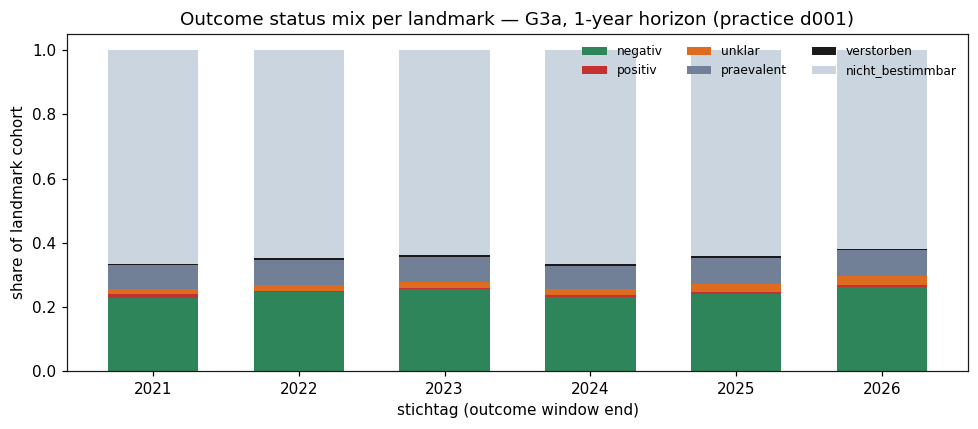

status,negativ,positiv,unklar,praevalent,verstorben,nicht_bestimmbar
stichtag,,,,,,
2021-07-01,0.228,0.012,0.018,0.073,0.004,0.665
2022-07-01,0.245,0.005,0.017,0.081,0.006,0.646
2023-07-01,0.257,0.003,0.019,0.077,0.005,0.638
2024-07-01,0.230,0.006,0.019,0.073,0.004,0.667
2025-07-01,0.242,0.006,0.025,0.080,0.006,0.641
2026-07-01,0.262,0.008,0.025,0.081,0.003,0.620


In [3]:
status_by_year = (
    df.assign(status=df[f"status_{LABEL}"])
      .groupby(["stichtag", "status"]).size().unstack(fill_value=0)
      .reindex(columns=["negativ", "positiv", "unklar", "praevalent", "verstorben", "nicht_bestimmbar"],
               fill_value=0)
)
share = status_by_year.div(status_by_year.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 4))
bottom = np.zeros(len(share))
colors = {"negativ": GREEN, "positiv": RED, "unklar": "#dd6b20",
          "praevalent": GREY, "verstorben": INK, "nicht_bestimmbar": "#cbd5e0"}
for col in share.columns:
    ax.bar(share.index.str[:4], share[col], bottom=bottom, label=col, color=colors[col], width=0.62)
    bottom += share[col].to_numpy()
ax.set_ylabel("share of landmark cohort"); ax.set_xlabel("stichtag (outcome window end)")
ax.set_title("Outcome status mix per landmark — G3a, 1-year horizon (practice d001)")
ax.legend(ncol=3, fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

share.round(3)

## 4. Cohort drift — does the practice population move?

Before crediting a model for getting better, check whether the *patients* got easier or harder.
Four clinically load-bearing features across landmarks, on the G3a-labelled cohort only.

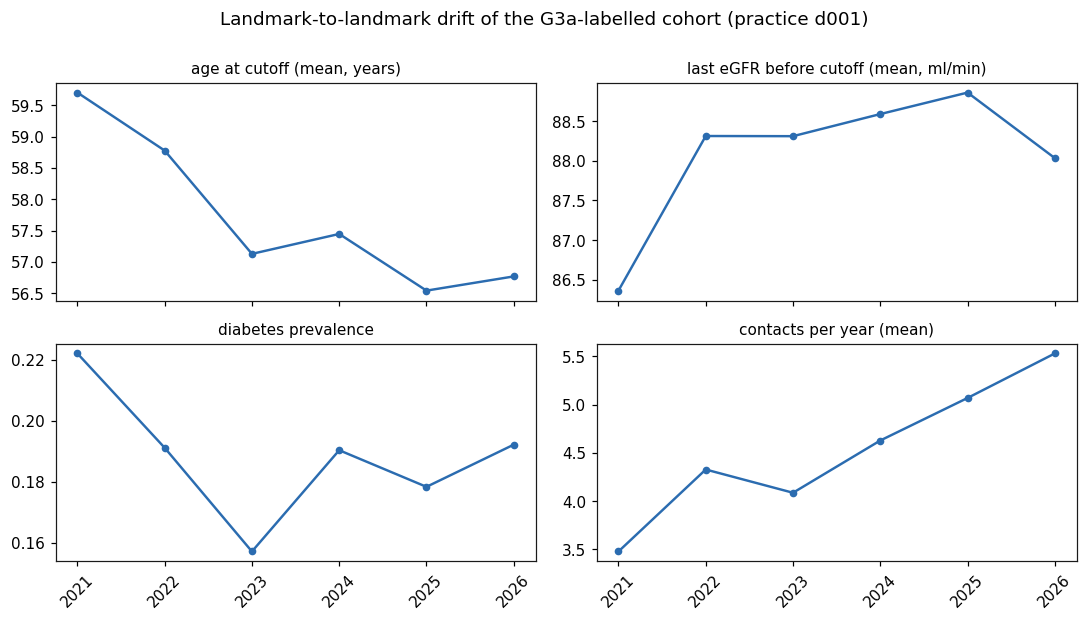

In [4]:
key_features = [
    ("alter_cutoff", "age at cutoff (mean, years)"),
    ("gfr_letzter", "last eGFR before cutoff (mean, ml/min)"),
    ("dm", "diabetes prevalence"),
    ("kontakte_pro_jahr", "contacts per year (mean)"),
]
lab = df[df[f"label_{LABEL}"].notna()]

fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), sharex=True)
for ax, (col, title) in zip(axes.ravel(), key_features):
    g = lab.groupby("stichtag")[col].mean()
    ax.plot(g.index.str[:4], g.values, "o-", color=BLUE, lw=1.6, ms=4)
    ax.set_title(title, fontsize=10); ax.tick_params(axis="x", rotation=45)
fig.suptitle("Landmark-to-landmark drift of the G3a-labelled cohort (practice d001)", y=1.0)
plt.tight_layout(); plt.show()

## 5. Evaluation protocol

Two complementary lenses, **AUPRC headlined** (AUROC alongside; the repo standard is AUROC +
sensitivity, but the question posed here is precision-recall skill on a rare event):

1. **Per-landmark out-of-fold (within-year skill):** for each landmark independently, the same
   ridge logistic regression (`Pipeline(StandardScaler -> LogisticRegression(l2, balanced))`),
   5-fold stratified OOF x 5 repeats; predicted probabilities averaged across repeats. AUPRC on
   the pooled OOF probabilities, with a 1000-draw patient-level bootstrap CI. The dashed
   reference line is the **no-skill baseline = that year's event rate** (AUPRC of a coin weighted
   by prevalence).
2. **Temporal transfer (deployment lens):** train on *all earlier landmarks pooled*, test on the
   next landmark — the exact "re-train each year on everything so far" loop a practice would run.
   Each landmark is a fresh snapshot of mostly the same patients, so earlier-landmark rows of a
   test patient legitimately sit in training (as they would in deployment); the evaluation is
   therefore time-disjoint, not patient-disjoint, by design.

Features: every CheCKD column except identifiers, run parameters and all `status_*` / `label_*`
columns (the notebook-06 exclusion contract), one fixed column order, no re-imputation (the SQL
already imputes with clinical constants); columns constant within a landmark cohort are dropped
for that fit only.

In [5]:
def build_xy(cohort):
    # CheCKD frame -> (X, y, feature names) via the repo dispatch; drop cohort-constant columns.
    X, y = to_xy(cohort, label=LABEL)
    feat = [c for c in cohort.columns
            if c not in ("praxis", "patientid", "stichtag", "cutoff", "horizont_jahre")
            and not c.startswith(("status_", "label_"))]
    keep = [i for i in range(X.shape[1]) if np.unique(X[:, i]).size > 1]
    return X[:, keep], y, [feat[i] for i in keep]


def oof_probs(X, y, seed=SEED, n_splits=5, n_repeats=5):
    # Repeat-averaged stratified OOF probabilities for the ridge logreg.
    probs = np.zeros((n_repeats, len(y)))
    for r in range(n_repeats):
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed + r)
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("lr", LogisticRegression(C=1.0, class_weight="balanced",
                                                   max_iter=2000, random_state=seed))])
        probs[r] = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
    return probs.mean(axis=0)


def boot_ci(y, p, seed=SEED, B=1000, fn=average_precision_score):
    # Patient-level bootstrap CI of a threshold metric on (y, p).
    rng = np.random.default_rng(seed)
    n, stats = len(y), []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        if y[idx].sum() < 1 or y[idx].sum() == len(idx):
            continue
        stats.append(fn(y[idx], p[idx]))
    return np.percentile(stats, [2.5, 50, 97.5])


def fit_proba(X_tr, y_tr, X_te, seed=SEED):
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("lr", LogisticRegression(C=1.0, class_weight="balanced",
                                               max_iter=2000, random_state=seed))])
    return pipe.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

## 6. Per-landmark skill — is one year's model better than the previous year's?

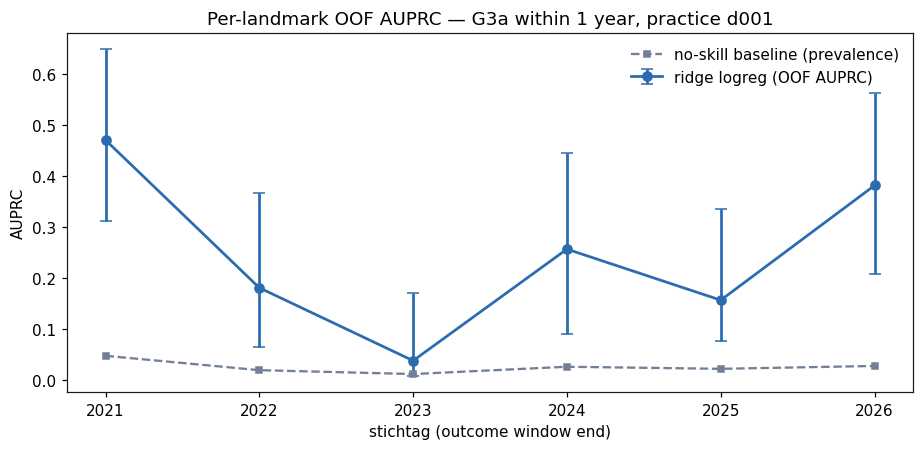

,N labelled,events,prevalence (=AP baseline),AUPRC,AUPRC 95% CI,AUROC,AUROC 95% CI,n features
stichtag,,,,,,,,
2021-07-01,707,34,0.048,0.484,"[0.315, 0.657]",0.910,"[0.852, 0.953]",62
2022-07-01,701,14,0.020,0.184,"[0.063, 0.377]",0.889,"[0.800, 0.949]",56
2023-07-01,808,10,0.012,0.040,"[0.009, 0.161]",0.588,"[0.335, 0.792]",56
2024-07-01,788,21,0.027,0.266,"[0.107, 0.466]",0.842,"[0.729, 0.920]",56
2025-07-01,841,19,0.023,0.170,"[0.075, 0.343]",0.838,"[0.721, 0.936]",70
2026-07-01,921,26,0.028,0.396,"[0.224, 0.571]",0.915,"[0.863, 0.955]",70


In [6]:
oof_results, oof_store = [], {}
for s in LANDMARKS:
    cohort = df[df["stichtag"] == s]
    X, y, feats = build_xy(cohort)
    p = oof_probs(X, y)
    oof_store[s] = (y, p)
    ap_lo, ap, ap_hi = boot_ci(y, p)
    au_lo, au, au_hi = boot_ci(y, p, fn=roc_auc_score)
    oof_results.append({
        "stichtag": s, "N labelled": len(y), "events": int(y.sum()),
        "prevalence (=AP baseline)": round(y.mean(), 3),
        "AUPRC": round(ap, 3), "AUPRC 95% CI": f"[{ap_lo:.3f}, {ap_hi:.3f}]",
        "AUROC": round(au, 3), "AUROC 95% CI": f"[{au_lo:.3f}, {au_hi:.3f}]",
        "n features": len(feats),
    })
oof_df = pd.DataFrame(oof_results).set_index("stichtag")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
years = [s[:4] for s in LANDMARKS]
aps = [average_precision_score(*oof_store[s]) for s in LANDMARKS]
lo = [boot_ci(*oof_store[s], seed=SEED + 7)[0] for s in LANDMARKS]
hi = [boot_ci(*oof_store[s], seed=SEED + 7)[2] for s in LANDMARKS]
ax.errorbar(years, aps, yerr=[np.array(aps) - np.array(lo), np.array(hi) - np.array(aps)],
            fmt="o-", color=BLUE, lw=1.8, capsize=4, label="ridge logreg (OOF AUPRC)")
prev = [oof_store[s][0].mean() for s in LANDMARKS]
ax.plot(years, prev, "s--", color=GREY, ms=4, label="no-skill baseline (prevalence)")
ax.set_ylabel("AUPRC"); ax.set_xlabel("stichtag (outcome window end)")
ax.set_title("Per-landmark OOF AUPRC — G3a within 1 year, practice d001")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

oof_df

## 7. Temporal transfer — does one extra year of history improve next year's prediction?

Train on every landmark up to and including year *t*, test on landmark *t+1*. This is the
federation-era question in miniature: more accumulated history should help *if* the practice's
data-generating process is roughly stationary.

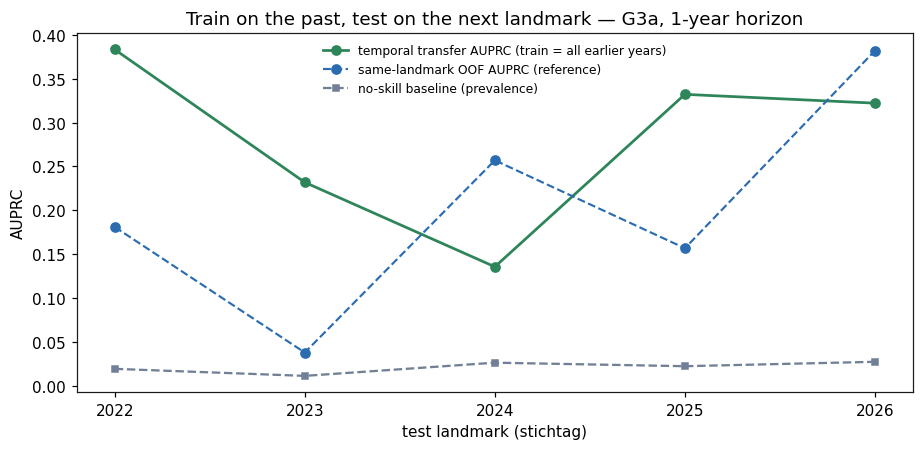

,train landmarks,test stichtag,test N,test events,prevalence (AP baseline),AUPRC,AUPRC 95% CI,AUROC,train N
0,2021,2022-07-01,701,14,0.020,0.383,"[0.126, 0.616]",0.920,707
1,...2022 (2),2023-07-01,808,10,0.012,0.232,"[0.043, 0.489]",0.838,1408
2,...2023 (3),2024-07-01,788,21,0.027,0.136,"[0.070, 0.237]",0.865,2216
3,...2024 (4),2025-07-01,841,19,0.023,0.332,"[0.143, 0.537]",0.906,3004
4,...2025 (5),2026-07-01,921,26,0.028,0.322,"[0.187, 0.491]",0.947,3845


In [7]:
temporal = []
for i in range(1, len(LANDMARKS)):
    tr_name, te_name = LANDMARKS[i - 1], LANDMARKS[i]
    tr = df[df["stichtag"].isin(LANDMARKS[:i])]
    te = df[df["stichtag"] == te_name]
    X_tr, y_tr, f_tr = build_xy(tr)
    X_te, y_te, f_te = build_xy(te)
    shared = [f for f in f_tr if f in set(f_te)]
    X_tr = X_tr[:, [f_tr.index(f) for f in shared]]
    X_te = X_te[:, [f_te.index(f) for f in shared]]
    p = fit_proba(X_tr, y_tr, X_te)
    ap_lo, ap, ap_hi = boot_ci(y_te, p)
    temporal.append({
        "train landmarks": f"...{tr_name[:4]} ({i})" if i > 1 else tr_name[:4],
        "test stichtag": te_name,
        "test N": len(y_te), "test events": int(y_te.sum()),
        "prevalence (AP baseline)": round(y_te.mean(), 3),
        "AUPRC": round(ap, 3), "AUPRC 95% CI": f"[{ap_lo:.3f}, {ap_hi:.3f}]",
        "AUROC": round(roc_auc_score(y_te, p), 3),
        "train N": len(y_tr),
    })
temporal_df = pd.DataFrame(temporal)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(temporal_df["test stichtag"].str[:4], temporal_df["AUPRC"], "o-",
        color=GREEN, lw=1.8, label="temporal transfer AUPRC (train = all earlier years)")
same_year_oof = [average_precision_score(*oof_store[s]) for s in LANDMARKS[1:]]
ax.plot(temporal_df["test stichtag"].str[:4], same_year_oof, "o--",
        color=BLUE, lw=1.4, label="same-landmark OOF AUPRC (reference)")
ax.plot(temporal_df["test stichtag"].str[:4], temporal_df["prevalence (AP baseline)"],
        "s--", color=GREY, ms=4, label="no-skill baseline (prevalence)")
ax.set_ylabel("AUPRC"); ax.set_xlabel("test landmark (stichtag)")
ax.set_title("Train on the past, test on the next landmark — G3a, 1-year horizon")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

temporal_df

## 8. Verdict — does AUPRC improve from 2021 to 2026?

Two numbers decide it:

1. the bootstrap CI of the **last-minus-first landmark OOF AUPRC difference** (within-year skill
   trend), and
2. whether the temporal-transfer AUPRC at the last test landmark sits **above** the first
   testable one beyond overlapping CIs.

In [8]:
rng = np.random.default_rng(SEED)

def boot_stat(y, p, B=2000):
    n, out = len(y), []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        if 0 < y[idx].sum() < len(idx):
            out.append(average_precision_score(y[idx], p[idx]))
    return np.array(out)

first, last = LANDMARKS[0], LANDMARKS[-1]
delta = boot_stat(*oof_store[last]) - boot_stat(*oof_store[first])
lo, med, hi = np.percentile(delta, [2.5, 50, 97.5])
print(f"OOF AUPRC {first[:4]}: {average_precision_score(*oof_store[first]):.3f}   "
      f"{last[:4]}: {average_precision_score(*oof_store[last]):.3f}")
print(f"difference (last - first): {med:+.3f}  with 95% bootstrap CI [{lo:+.3f}, {hi:+.3f}]")
print()
t_first, t_last = temporal_df.iloc[0], temporal_df.iloc[-1]
print(f"Temporal transfer AUPRC - test {t_first['test stichtag'][:4]}: {t_first['AUPRC']:.3f}, "
      f"test {t_last['test stichtag'][:4]}: {t_last['AUPRC']:.3f}")
print()
verdict = ("CI excludes 0 and is positive: within-year skill IMPROVED."
           if lo > 0 else
           "CI includes 0: no evidence that per-landmark AUPRC improved across 2021→2026.")
print("VERDICT:", verdict)

OOF AUPRC 2021: 0.471   2026: 0.382
difference (last - first): -0.089  with 95% bootstrap CI [-0.335, +0.159]

Temporal transfer AUPRC - test 2022: 0.383, test 2026: 0.322

VERDICT: CI includes 0: no evidence that per-landmark AUPRC improved across 2021→2026.


## 9. Reading the result

- If the AUPRC curve is flat while the prevalence baseline (dashed) moves, the model tracks the
  cohort but history adds nothing measurable — a flatness *result*, not a failure.
- Event counts here are 10–34 per landmark: at this size, year-to-year AUPRC swings of several
  points are sampling noise. The honest claim is always the CI, never the point estimate.
- The surveillance selection (`nicht_bestimmbar` share) and cohort drift (section 4) bound how
  far any improvement can be credited to "more data" versus "an easier cohort".
- What *would* move AUPRC at this event rate is more labelled events — i.e. exactly the
  multi-practice pooling the federated pipeline provides. This notebook is the single-practice
  evidence for that argument.

*Data: `practice_1/landmarks_1j_2021_2026_d001.csv` (CheCKD SQL, six landmarks, horizon 1 y,
practice d001). Model: ridge logistic regression only (project rule: no other class is
federatable). Metric: average precision (AUPRC), patient-level bootstrap CIs, seed 42.*